# Section 1: Data Cleaning

## About the Data
The dataset is **Zomato Bangalore Restaurants** (Kaggle, by Himanshu Poddar). It was scraped from Zomato's listing pages and describes restaurants in Bangalore, India.

- **Size:** 51,717 rows × 17 columns
- **Important detail:** each row is a *listing* of a restaurant, not a restaurant. The same restaurant appears several times, once for each category list it was shown in (`listed_in(type)`), so the data contains only about 12,500 distinct restaurants.

| Column | Description |
|---|---|
| `name`, `address` | Restaurant name and street address (together they identify a restaurant) |
| `online_order`, `book_table` | Whether the restaurant offers online ordering / table booking (Yes/No) |
| `rate` | Customer rating out of 5 (stored as text, e.g. `"4.1/5"`; `NEW` and `-` mean not yet rated) |
| `votes` | Number of ratings given |
| `location` | Neighbourhood in Bangalore |
| `rest_type` | Type of restaurant (multivalued, e.g. `"Cafe, Casual Dining"`) |
| `cuisines` | Cuisines served (multivalued) |
| `dish_liked` | Dishes customers liked (multivalued, about half missing) |
| `approx_cost(for two people)` | Approximate cost for two people (stored as text) |
| `listed_in(type)`, `listed_in(city)` | The list the restaurant was scraped from (a category, and a location) |
| `url`, `phone`, `menu_item`, `reviews_list` | Identifiers and raw text |

## Objective
**Predict a restaurant's rating (`rate`)** from its features, using two framings:

1. **Regression:** predict the numeric rating.
2. **Classification:** predict whether a restaurant is *good* or *not good*, where the label is made by thresholding `rate`.

The models to apply are Linear Regression, Logistic Regression, Decision Trees, Naive Bayes, KNN, SVM, Bagging and Boosting.

## Plan for This Section
1. Inspect the data and find its quality problems.
2. Clean `rate` and keep only restaurants that have a rating (it is our target, so it is never imputed).
3. Convert `approx_cost` to a number and `online_order`/`book_table` to 1/0.
4. **Deduplicate** to one row per restaurant, using `name` + `address` as the key. Before collapsing, merge the categories from `listed_in(type)` so that information is not lost.
5. Build simple helper features that do not use the target (chain size, number of cuisines, and so on).
6. Handle the remaining missing values, and drop identifier and raw text columns.

**Rule followed throughout:** no step here uses the target `rate` to create a feature, so the cleaned data is safe to use before the train/test split.

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
df = pd.read_csv('zomato.csv')

In [66]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [67]:
df.shape

(51717, 17)

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [69]:
df['approx_cost(for two people)'].unique()

<StringArray>
[  '800',   '300',   '600',   '700',   '550',   '500',   '450',   '650',
   '400',   '900',   '200',   '750',   '150',   '850',   '100', '1,200',
   '350',   '250',   '950', '1,000', '1,500', '1,300',   '199',    '80',
 '1,100',   '160', '1,600',   '230',   '130',    '50',   '190', '1,700',
     nan, '1,400',   '180', '1,350', '2,200', '2,000', '1,800', '1,900',
   '330', '2,500', '2,100', '3,000', '2,800', '3,400',    '40', '1,250',
 '3,500', '4,000', '2,400', '2,600',   '120', '1,450',   '469',    '70',
 '3,200',    '60',   '560',   '240',   '360', '6,000', '1,050', '2,300',
 '4,100', '5,000', '3,700', '1,650', '2,700', '4,500',   '140']
Length: 71, dtype: str

In [70]:
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].str.replace(',', '').astype(float)

In [71]:
df['approx_cost(for two people)'].unique()

array([ 800.,  300.,  600.,  700.,  550.,  500.,  450.,  650.,  400.,
        900.,  200.,  750.,  150.,  850.,  100., 1200.,  350.,  250.,
        950., 1000., 1500., 1300.,  199.,   80., 1100.,  160., 1600.,
        230.,  130.,   50.,  190., 1700.,   nan, 1400.,  180., 1350.,
       2200., 2000., 1800., 1900.,  330., 2500., 2100., 3000., 2800.,
       3400.,   40., 1250., 3500., 4000., 2400., 2600.,  120., 1450.,
        469.,   70., 3200.,   60.,  560.,  240.,  360., 6000., 1050.,
       2300., 4100., 5000., 3700., 1650., 2700., 4500.,  140.])

In [72]:
print("Online Order Values:\n----------\n", df['online_order'].value_counts())
print()
print("Book Table Values:\n----------\n", df['book_table'].value_counts())

Online Order Values:
----------
 online_order
Yes    30444
No     21273
Name: count, dtype: int64

Book Table Values:
----------
 book_table
No     45268
Yes     6449
Name: count, dtype: int64


In [73]:
mapping = {'Yes': 1, 'No': 0}
df['online_order'] = df['online_order'].map(mapping)
df['book_table'] = df['book_table'].map(mapping)

In [74]:
df['online_order'].value_counts()

online_order
1    30444
0    21273
Name: count, dtype: int64

In [75]:
df['book_table'].value_counts()

book_table
0    45268
1     6449
Name: count, dtype: int64

`approx_cost(for two people)` data type from str to float <br>
`online_order` and `book_table` encoded to 1/0

Checking for the data identifier, and which one we will check duplicates on

In [76]:
df['url'].nunique()

51717

In [77]:
df.groupby('url')[['rate','votes']].nunique().max()

rate     1
votes    1
dtype: int64

Here we see that each row has a unique `url` so deduplicating by it will be meaningless

Cleaning Rate Column

In [78]:
df['rate'].unique()

<StringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',    'NEW',  '2.9/5',  '3.5/5',      nan,  '2.6/5', '3.8 /5',
  '3.4/5',  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',
  '2.3/5', '3.4 /5',      '-', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5',
 '4.0 /5', '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
 '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5',
 '4.4 /5',  '4.9/5',  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5',
 '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5',
 '2.0 /5', '1.8 /5']
Length: 65, dtype: str

In [79]:
df['rate'] = (df['rate'].replace(['NEW', '-'], np.nan).str.replace('/5', '', regex=False).str.strip().astype(float))    

In [80]:
df['rate'].unique()

array([4.1, 3.8, 3.7, 3.6, 4.6, 4. , 4.2, 3.9, 3.1, 3. , 3.2, 3.3, 2.8,
       4.4, 4.3, nan, 2.9, 3.5, 2.6, 3.4, 4.5, 2.5, 2.7, 4.7, 2.4, 2.2,
       2.3, 4.8, 4.9, 2.1, 2. , 1.8])

In [81]:
df = df.dropna(subset=['rate']).reset_index(drop=True)

In [82]:
df.shape

(41665, 17)

In [83]:
df['location'].unique()

<StringArray>
[                 'Banashankari',                  'Basavanagudi',
                   'Mysore Road',                     'Jayanagar',
            'Kumaraswamy Layout',          'Rajarajeshwari Nagar',
                   'Vijay Nagar',                   'Uttarahalli',
                      'JP Nagar',               'South Bangalore',
                   'City Market',             'Bannerghatta Road',
                           'BTM',               'Kanakapura Road',
                  'Bommanahalli',               'Electronic City',
                 'Sarjapur Road',                 'Wilson Garden',
                  'Shanti Nagar',         'Koramangala 5th Block',
                 'Richmond Road',                           'HSR',
         'Koramangala 7th Block',                     'Bellandur',
                  'Marathahalli',                    'Whitefield',
                'East Bangalore',              'Old Airport Road',
                   'Indiranagar',         'Koram

In [84]:
df['listed_in(city)'].unique()

<StringArray>
[         'Banashankari',     'Bannerghatta Road',          'Basavanagudi',
             'Bellandur',          'Brigade Road',           'Brookefield',
                   'BTM',         'Church Street',       'Electronic City',
           'Frazer Town',                   'HSR',           'Indiranagar',
             'Jayanagar',              'JP Nagar',          'Kalyan Nagar',
          'Kammanahalli', 'Koramangala 4th Block', 'Koramangala 5th Block',
 'Koramangala 6th Block', 'Koramangala 7th Block',          'Lavelle Road',
          'Malleshwaram',          'Marathahalli',               'MG Road',
          'New BEL Road',      'Old Airport Road',           'Rajajinagar',
        'Residency Road',         'Sarjapur Road',            'Whitefield']
Length: 30, dtype: str

In [85]:
def isCityinLocation(column):
    col = df[column].unique()
    count = 0
    locations = df['location'].unique()
    for i in col:
        if i not in locations: count += 1
    return count

citiesNotinLocation = isCityinLocation('listed_in(city)')
print(citiesNotinLocation)

0


#### using the function `isCityinLocation` we make sure that the column `listed_in(city)` is redundant

In [86]:
df = df.drop(['listed_in(city)'], axis=1)

## Deduplicate to one row per restaurant

In [87]:
key = ['name', 'address']
base = (df.sort_values('votes', ascending=False)
          .groupby(key, sort=False).first().drop(columns=['listed_in(type)']))
base

,,url,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item
name,address,,,,,,,,,,,,,
Byg Brewski Brewing Company,"Behind MK Retail, Sarjapur Road, Bangalore",https://www.zomato.com/bangalore/byg-brewski-b...,1,1,4.9,16832,+91 8039514766,Sarjapur Road,Microbrewery,"Cocktails, Butter Chicken, Dahi Kebab, Rajma C...","Continental, North Indian, Italian, South Indi...",1600.0,"[('Rated 5.0', ""RATED\n This is an absolute g...",[]
Toit,"298, Namma Metro Pillar 62, 100 Feet Road, Indiranagar, Bangalore",https://www.zomato.com/bangalore/toit-indirana...,0,0,4.7,14956,+91 9019713388,Indiranagar,Microbrewery,"Beer, Pesto Pizza, Nachos, Cocktails, Beef Las...","Italian, American, Pizza",1500.0,"[('Rated 4.0', ""RATED\n The crowd keeps flowi...",[]
Truffles,"28, 4th 'B' Cross, Koramangala 5th Block, Bangalore",https://www.zomato.com/bangalore/truffles-kora...,0,0,4.7,14726,080 49652818,Koramangala 5th Block,"Cafe, Casual Dining","Burgers, Pasta, Cocktails, American Cheese Bur...","Cafe, American, Burger, Steak",900.0,"[('Rated 3.0', ""RATED\n Not bad but the burge...",[]
AB's - Absolute Barbecues,"90/4, 3rd Floor, Outer Ring Road, Munnekollaly Village, Marathahalli, Bangalore",https://www.zomato.com/bangalore/abs-absolute-...,0,1,4.8,12121,080 49652574,Marathahalli,Casual Dining,"Raj Kachori, Paan Kulfi, Churros, Butter Chick...","European, Mediterranean, North Indian, BBQ",1600.0,"[('Rated 4.0', 'RATED\n We came here for a te...",[]
The Black Pearl,"105, 1st A Cross Road, Jyothi Nivas College Road, Koramangala 5th Block, Bangalore",https://www.zomato.com/bangalore/the-black-pea...,0,1,4.7,10550,080 49652452,Koramangala 5th Block,"Casual Dining, Bar","Chocolate Lollipop, Chocolate Biscuit, Fire Sh...","North Indian, European, Mediterranean",1400.0,"[('Rated 5.0', 'RATED\n Amazing experience am...",[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Crave Bit Cafe,"Amoolya, 1st Floor, 24th Main, 6th Phase, JP Nagar, Bangalore",https://www.zomato.com/bangalore/crave-bit-caf...,0,0,3.7,0,080 42061006,JP Nagar,Cafe,NaN,Cafe,600.0,"[('Rated 5.0', 'RATED\n ItÃ\x83Ã\x83Ã\x82Ã...",[]
Desi Aahar,"44, 1st Floor, 100 Feet Ring Road, Above Vijaya Bank ATM, Vysya Bank Colony, 2nd Stage, BTM, Bangalore",https://www.zomato.com/bangalore/desi-aahar-bt...,1,0,3.3,0,+91 8043772280\r\n+91 9632511981,BTM,Quick Bites,NaN,"North Indian, Chinese, Seafood",400.0,"[('Rated 5.0', 'RATED\n Great foo and taste a...","['Chicken Biryani', 'Mutton Biryani', 'Mutton ..."
The Punjabi Rasoi,"952, 1st Floor, 24th Main, 2nd Phase, JP Nagar, Bangalore",https://www.zomato.com/bangalore/the-punjabi-r...,0,0,3.4,0,080 42085222,JP Nagar,Casual Dining,NaN,North Indian,800.0,"[('Rated 4.0', ""RATED\n I love punjabi food a...",[]


In [88]:
raw = pd.read_csv('zomato.csv', usecols=['name', 'address', 'listed_in(type)'])

# each name, address may be duplicated because of multiple types , so we hot-encode the types and then an OR is done between 
# common name, address to get a single row for each restaurant with all the types it belongs to
type_flags = (pd.get_dummies(raw['listed_in(type)'], prefix='type').astype(int)
                .join(raw[key]).groupby(key).max())      

# add the ones in each row to know this restaurant belongs to how many types
type_flags['n_types'] = type_flags.sum(axis=1)
type_flags

type_Buffet  \
name                                         address                                                           
#FeelTheROLL                                 Opposite Mantri Commercio, Outer Ring Road, Dev...            0   
#L-81 Cafe                                   Sector 6, HSR Layout, HSR                                     0   
#Vibes Restro                                Marasur Gate, Chandapura - Anekal Road, Near Al...            1   
#refuel                                      7, Ground Floor, RR Commercial Complex, Akshay ...            0   
'Brahmins' Thatte Idli                       19, 1st main, 2nd cross, 3rd stage, 3rd block, ...            0   
...                                                                                                      ...   
nu.tree                                      47/7 First floor, DoddaThogur Road, Near Velank...            0   
                                             Ground Floor-Lobby Area, Brigade IRV Centre, Na...            0   
re:cess - Hilton Bangalore Embassy GolfLinks Hilton Bangalore Embassy GolfLinks, Embassy Gol...            0   
repEAT Hub                                   67/4, Bhoganahalli Road, JCR Layout, Panathur, ...            0   
sCoolMeal                                    197/293-3, 32nd Main, 1st Stage, BTM, Bangalore               0   

                                                                                                 type_Cafes  \
name                                         address                                                          
#FeelTheROLL                                 Opposite Mantri Commercio, Outer Ring Road, Dev...           0   
#L-81 Cafe                                   Sector 6, HSR Layout, HSR                                    0   
#Vibes Restro                                Marasur Gate, Chandapura - Anekal Road, Near Al...           0   
#refuel                                      7, Ground Floor, RR Commercial Complex, Akshay ...           1   
'Brahmins' Thatte Idli                       19, 1st main, 2nd cross, 3rd stage, 3rd block, ...           0   
...                                                                                                     ...   
nu.tree                                      47/7 First floor, DoddaThogur Road, Near Velank...           0   
                                             Ground Floor-Lobby Area, Brigade IRV Centre, Na...           0   
re:cess - Hilton Bangalore Embassy GolfLinks Hilton Bangalore Embassy GolfLinks, Embassy Gol...           0   
repEAT Hub                                   67/4, Bhoganahalli Road, JCR Layout, Panathur, ...           0   
sCoolMeal                                    197/293-3, 32nd Main, 1st Stage, BTM, Bangalore              0   

                                                                                                 type_Delivery  \
name                                         address                                                             
#FeelTheROLL                                 Opposite Mantri Commercio, Outer Ring Road, Dev...              1   
#L-81 Cafe                                   Sector 6, HSR Layout, HSR                                       1   
#Vibes Restro                                Marasur Gate, Chandapura - Anekal Road, Near Al...              1   
#refuel                                      7, Ground Floor, RR Commercial Complex, Akshay ...              1   
'Brahmins' Thatte Idli                       19, 1st main, 2nd cross, 3rd stage, 3rd block, ...              0   
...                                                                                                        ...   
nu.tree                                      47/7 First floor, DoddaThogur Road, Near Velank...              1   
                                             Ground Floor-Lobby Area, Brigade IRV Centre, Na...              1   
re:cess - Hilton Bangalore Embassy GolfLinks Hilton Bang

In [89]:
df = base.join(type_flags, how='left').reset_index()
print(df.shape)                     
print(df['n_types'].value_counts())

(9507, 23)
n_types
2    4910
1    3569
3     812
4     198
5      17
6       1
Name: count, dtype: int64


In [90]:
df.duplicated().sum()

np.int64(0)

Each restaurant appears once per `listed_in(type)` category, so we one-hot encoded that column, merged the rows sharing the same `name` + `address` by taking the max (OR) of each category flag, and kept a single row per restaurant, which preserves every category it was listed under.

**Helper features:** we derive simple features from the identifier and multivalued columns (chain size, number of cuisines and restaurant types, and whether dish and menu information exists), none of which uses the target `rate`.

In [ ]:
df['n_outlets'] = df.groupby('name')['address'].transform('nunique')
df['is_chain']  = (df['n_outlets'] > 1).astype(int)
df['n_cuisines'] = df['cuisines'].str.split(',').str.len()
df['n_rest_types'] = df['rest_type'].str.split(',').str.len()
df['has_dish_liked'] = df['dish_liked'].notna().astype(int)
df['has_menu'] = (df['menu_item'] != '[]').astype(int)

In [94]:
df.isna().sum()[lambda x: x > 0]

phone                           159
rest_type                        36
dish_liked                     4864
cuisines                          4
approx_cost(for two people)      29
n_cuisines                        4
n_rest_types                     36
dtype: int64

In [95]:
df = df.drop(columns=['url', 'phone', 'dish_liked', 'menu_item', 'reviews_list', 'name', 'address'])

## Final Checks and Saving the clean data

In [97]:
df = df.dropna().reset_index(drop=True)
df.shape

(9438, 22)

In [98]:
df.isna().sum()[lambda x: x > 0]

Series([], dtype: int64)

In [99]:
print("------ Zomato Dataset Info ------")
print("Shape: ", df.shape)
print("Nulls: ", df.isna().sum().sum())
print("Duplicates: ", df.duplicated().sum())
print("Dtypes: \n", df.dtypes)

------ Zomato Dataset Info ------
Shape:  (9438, 22)
Nulls:  0
Duplicates:  16
Dtypes: 
 online_order                     int64
book_table                       int64
rate                           float64
votes                            int64
location                           str
rest_type                          str
cuisines                           str
approx_cost(for two people)    float64
type_Buffet                      int64
type_Cafes                       int64
type_Delivery                    int64
type_Desserts                    int64
type_Dine-out                    int64
type_Drinks & nightlife          int64
type_Pubs and bars               int64
n_types                          int64
n_outlets                        int64
is_chain                         int64
n_cuisines                     float64
n_rest_types                   float64
has_dish_liked                   int64
has_menu                         int64
dtype: object


In [104]:
df.to_csv('zomato_clean.csv', index=False)

## Section 1 Summary
- Converted `approx_cost` to numeric, `online_order` and `book_table` to 1/0, and `rate` to float
- Dropped unrated restaurants (`rate` is the target, so it is never imputed)
- Deduplicated to one row per restaurant (`name` + `address`), merging all `listed_in(type)` categories into `type_` flags
- Created helper features: `n_types`, `n_outlets`, `is_chain`, `n_cuisines`, `n_rest_types`, `has_dish_liked`, `has_menu`
- Dropped identifier and raw text columns, and rows with missing values (about 1%)
- Final data: 9,438 restaurants × 22 columns, saved as `zomato_clean.csv`

---

# Section 2: Visualization

In this section we explore the cleaned data visually: the distribution of the target `rate`, how it relates to the features, and which categories are most common. Nothing is transformed or fitted here, so all charts use the full cleaned data.

In [105]:
df_clean = pd.read_csv('zomato_clean.csv')
df_clean = df_clean.rename(columns={'approx_cost(for two people)': 'cost2people'})
df_clean[['n_cuisines', 'n_rest_types']] = df_clean[['n_cuisines', 'n_rest_types']].astype(int)

sns.set_theme(style='whitegrid')
type_cols = [c for c in df.columns if c.startswith('type_')]
df.shape

(9438, 22)

### The target: rate

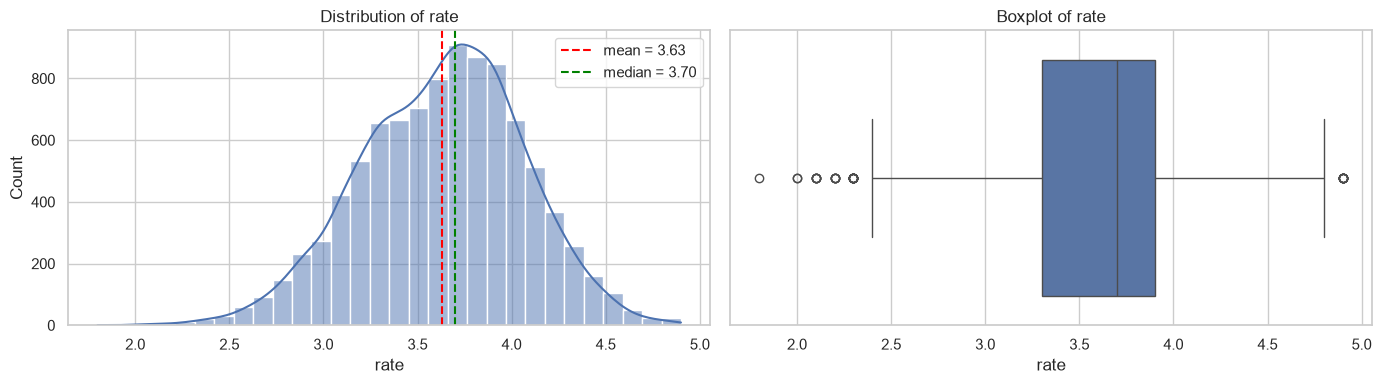

count    9438.000000
mean        3.628438
std         0.430060
min         1.800000
25%         3.300000
50%         3.700000
75%         3.900000
max         4.900000
Name: rate, dtype: float64
skew: -0.21


In [107]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['rate'], bins=30, kde=True, ax=ax[0])
ax[0].axvline(df['rate'].mean(), color='red', ls='--', label=f"mean = {df['rate'].mean():.2f}")
ax[0].axvline(df['rate'].median(), color='green', ls='--', label=f"median = {df['rate'].median():.2f}")
ax[0].legend(); 
ax[0].set_title('Distribution of rate')

sns.boxplot(x=df['rate'], ax=ax[1]); ax[1].set_title('Boxplot of rate')
plt.tight_layout(); plt.show()

print(df['rate'].describe())
print('skew:', round(df['rate'].skew(), 2))

**Observation:** `rate` is roughly normal with a slight left skew (mean 3.63, median 3.70, std 0.43). Half of the restaurants fall between 3.3 and 3.9, and the few extreme values (1.8–2.3 and 4.9) are genuine ratings, so they are kept. 

### Distribution of votes and cost

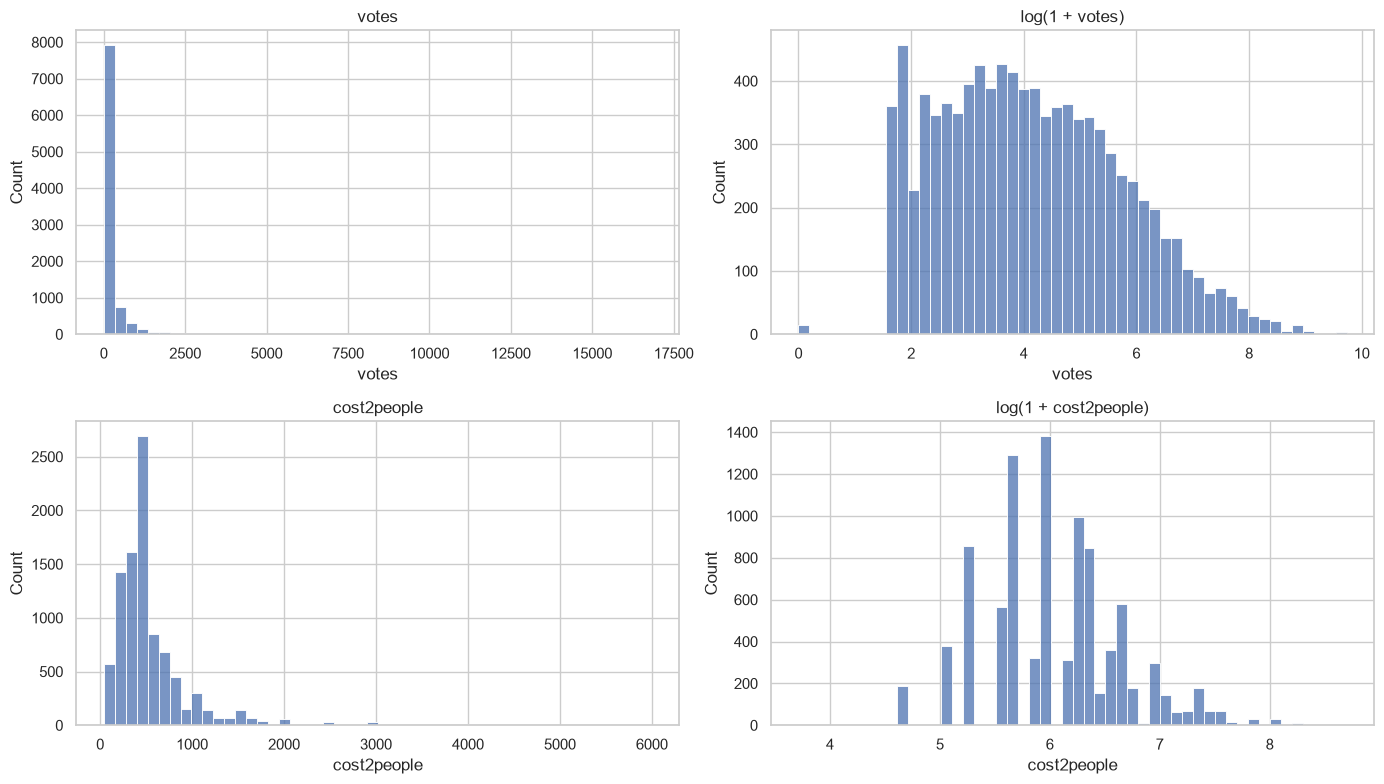

              votes  cost2people
count   9438.000000  9438.000000
mean     242.534329   536.132549
std      678.856545   425.315112
min        0.000000    40.000000
25%       16.000000   300.000000
50%       53.000000   400.000000
75%      189.750000   600.000000
max    16832.000000  6000.000000
skew raw: {'votes': 9.12, 'cost2people': 3.21}
skew log: {'votes': 0.39, 'cost2people': 0.3}


In [110]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
sns.histplot(df_clean['votes'], bins=50, ax=ax[0, 0]);            
ax[0, 0].set_title('votes')

sns.histplot(np.log1p(df_clean['votes']), bins=50, ax=ax[0, 1])
ax[0, 1].set_title('log(1 + votes)')

sns.histplot(df_clean['cost2people'], bins=50, ax=ax[1, 0])   
ax[1, 0].set_title('cost2people')

sns.histplot(np.log1p(df_clean['cost2people']), bins=50, ax=ax[1, 1])
ax[1, 1].set_title('log(1 + cost2people)')

plt.tight_layout()
plt.show()

print(df_clean[['votes', 'cost2people']].describe())
print('skew raw:', df_clean[['votes', 'cost2people']].skew().round(2).to_dict())
print('skew log:', np.log1p(df_clean[['votes', 'cost2people']]).skew().round(2).to_dict())

**Observation:** Both `votes` and `cost` are strongly right-skewed (skew 9.12 and 3.21): most restaurants have few votes (median 53) and a moderate cost (median 400), while a few reach 16,832 votes or a cost of 6,000. After a log(1 + x) transform the skew drops to 0.39 and 0.30, so we will apply it before the distance-based and linear models. The extreme values are real restaurants, so they are kept. No rated restaurant has only 1–4 votes, which suggests Zomato shows a rating only after a few votes.

### Binary features vs rate

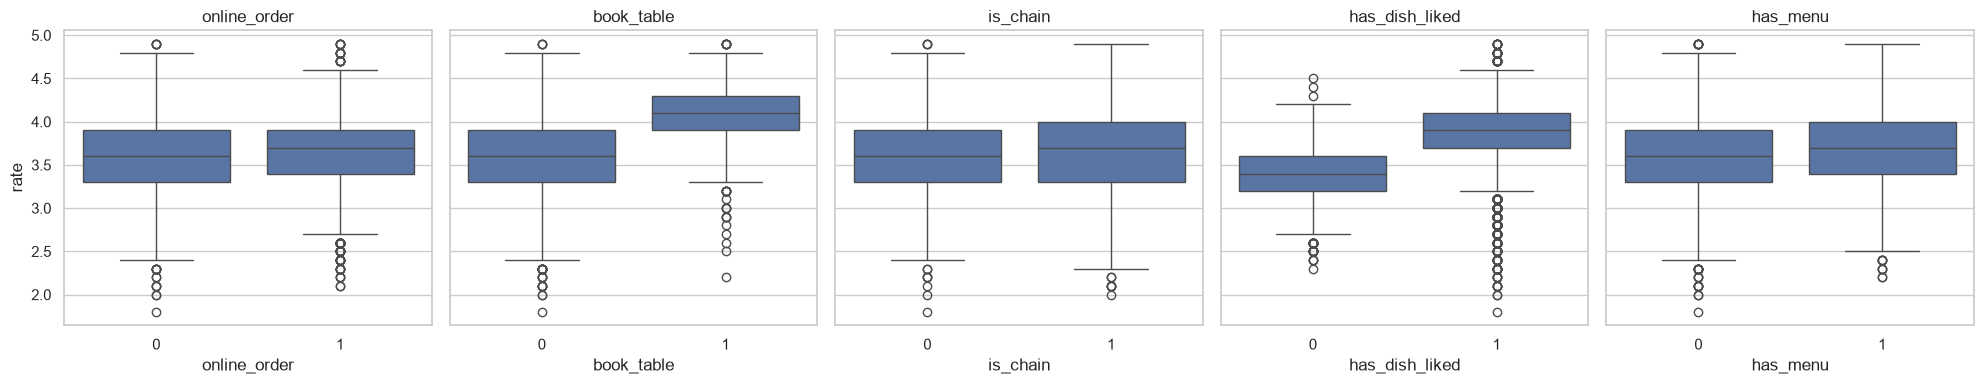

In [119]:
bin_cols = ['online_order', 'book_table', 'is_chain', 'has_dish_liked', 'has_menu']

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, c in zip(axes, bin_cols):
    sns.boxplot(data=df, x=c, y='rate', ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

 *Observation:* `book_table` and `has_dish_liked` separate ratings clearly: restaurants that accept table bookings have a median rate of about 4.1 versus 3.6, and those with liked dishes about 3.9 versus 3.4. `has_dish_liked` is probably also a proxy for popularity, since dishes appear once a restaurant has enough reviews, so we will check its overlap with `votes`. `online_order`, `is_chain` and `has_menu` show only a small shift (about 0.1), so they are weaker individual predictors.

### votes and cost vs rate

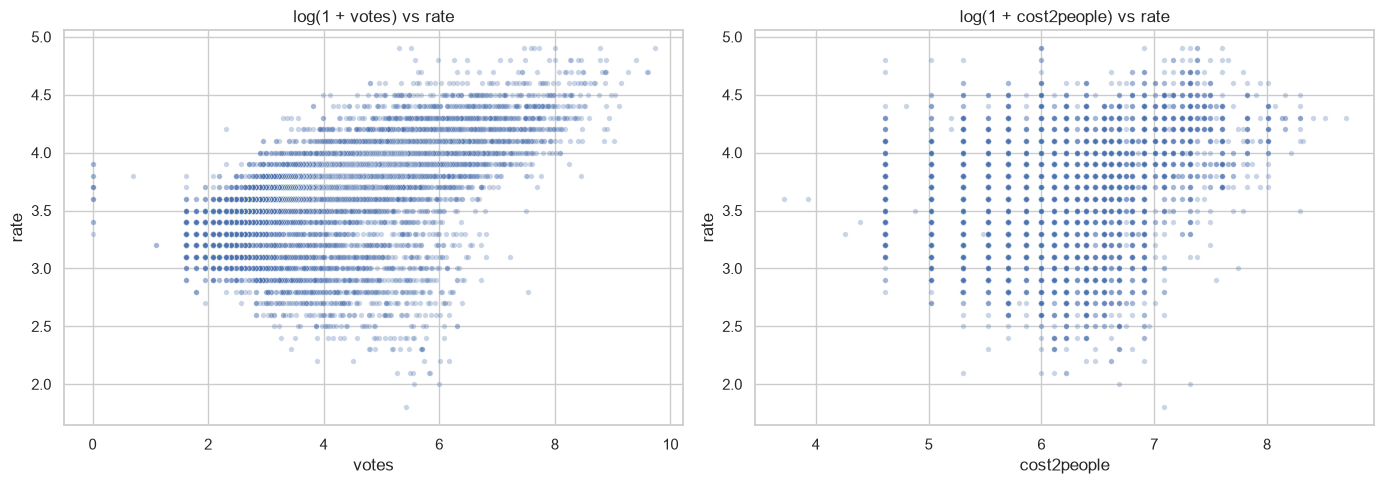

In [117]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=np.log1p(df_clean['votes']), y=df['rate'], alpha=0.3, s=15, ax=ax[0])
ax[0].set_title('log(1 + votes) vs rate')
sns.scatterplot(x=np.log1p(df_clean['cost2people']), y=df['rate'], alpha=0.3, s=15, ax=ax[1])
ax[1].set_title('log(1 + cost2people) vs rate')
plt.tight_layout()
plt.show()

**Observation:** `rate` rises with `log(votes)`: restaurants with few votes mostly lie between 2.7 and 3.9, while those with many votes are almost all rated 3.8 or higher, so `votes` looks like a strong predictor. `cost` shows a weaker, non-linear relationship: low and mid-priced restaurants span the full range of ratings, but expensive ones (above about 1,100) rarely fall below 3.5. The spread of ratings does not shrink as votes increase, so there is no sign that low-vote ratings are just noisy versions of the same value, and we keep `rate` unweighted.

### Location

distinct locations: 92


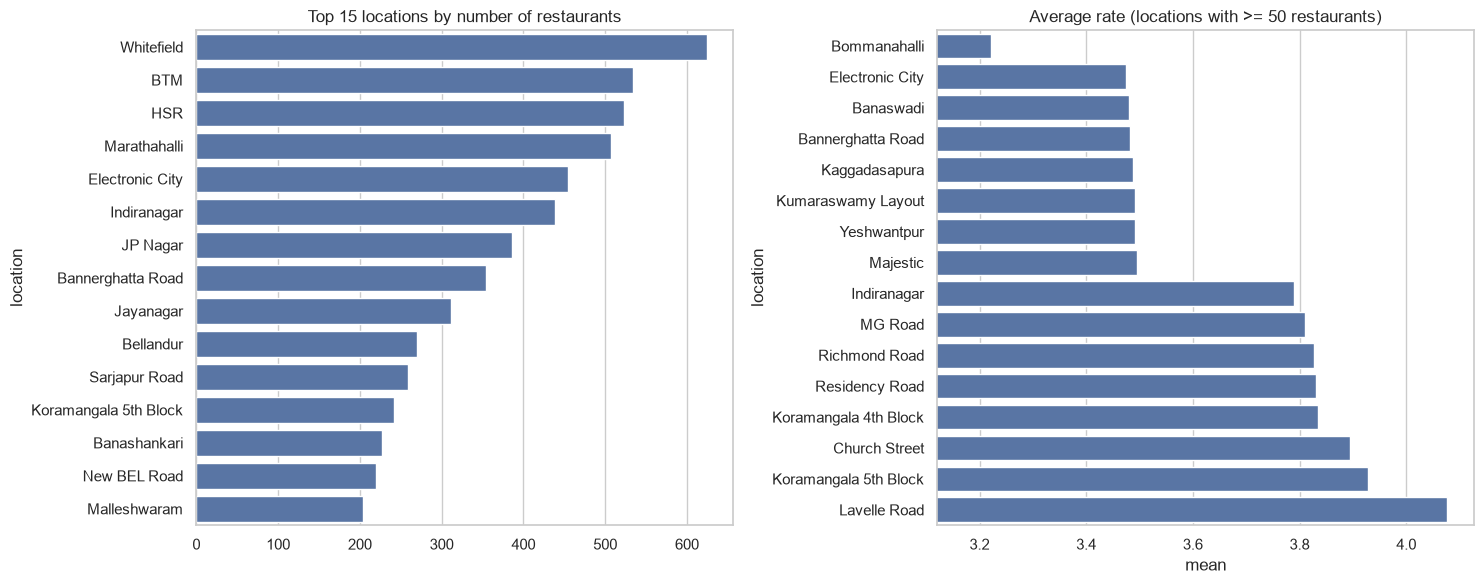

In [120]:
loc_stats = df_clean.groupby('location')['rate'].agg(['mean', 'count'])
print('distinct locations:', len(loc_stats))

top_loc = df_clean['location'].value_counts().head(15)
sel = loc_stats[loc_stats['count'] >= 50].sort_values('mean')
sel = pd.concat([sel.head(8), sel.tail(8)])          

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=top_loc.values, y=top_loc.index, ax=ax[0])
ax[0].set_title('Top 15 locations by number of restaurants')
sns.barplot(x=sel['mean'], y=sel.index, ax=ax[1])
ax[1].set_xlim(sel['mean'].min() - 0.1, sel['mean'].max() + 0.05)   
ax[1].set_title('Average rate (locations with >= 50 restaurants)')
plt.tight_layout(); plt.show()

**Observation:** The 92 locations are very unevenly populated: Whitefield (about 625 restaurants), BTM, HSR, Marathahalli and Electronic City lead, while many locations have only a few restaurants. Average ratings differ a lot between locations, from about 3.2 (Bommanahalli) to about 4.1 (Lavelle Road), roughly twice the overall standard deviation of `rate`. The highest averages belong to central areas (Lavelle Road, Koramangala, Church Street, MG Road), and the lowest to outer areas such as Bommanahalli, Electronic City and Kaggadasapura (note that the right-hand axis does not start at zero). Since `location` is informative but has many categories, we will encode only the most frequent ones (or use a smoothed target encoding fitted on the training set) in preprocessing.

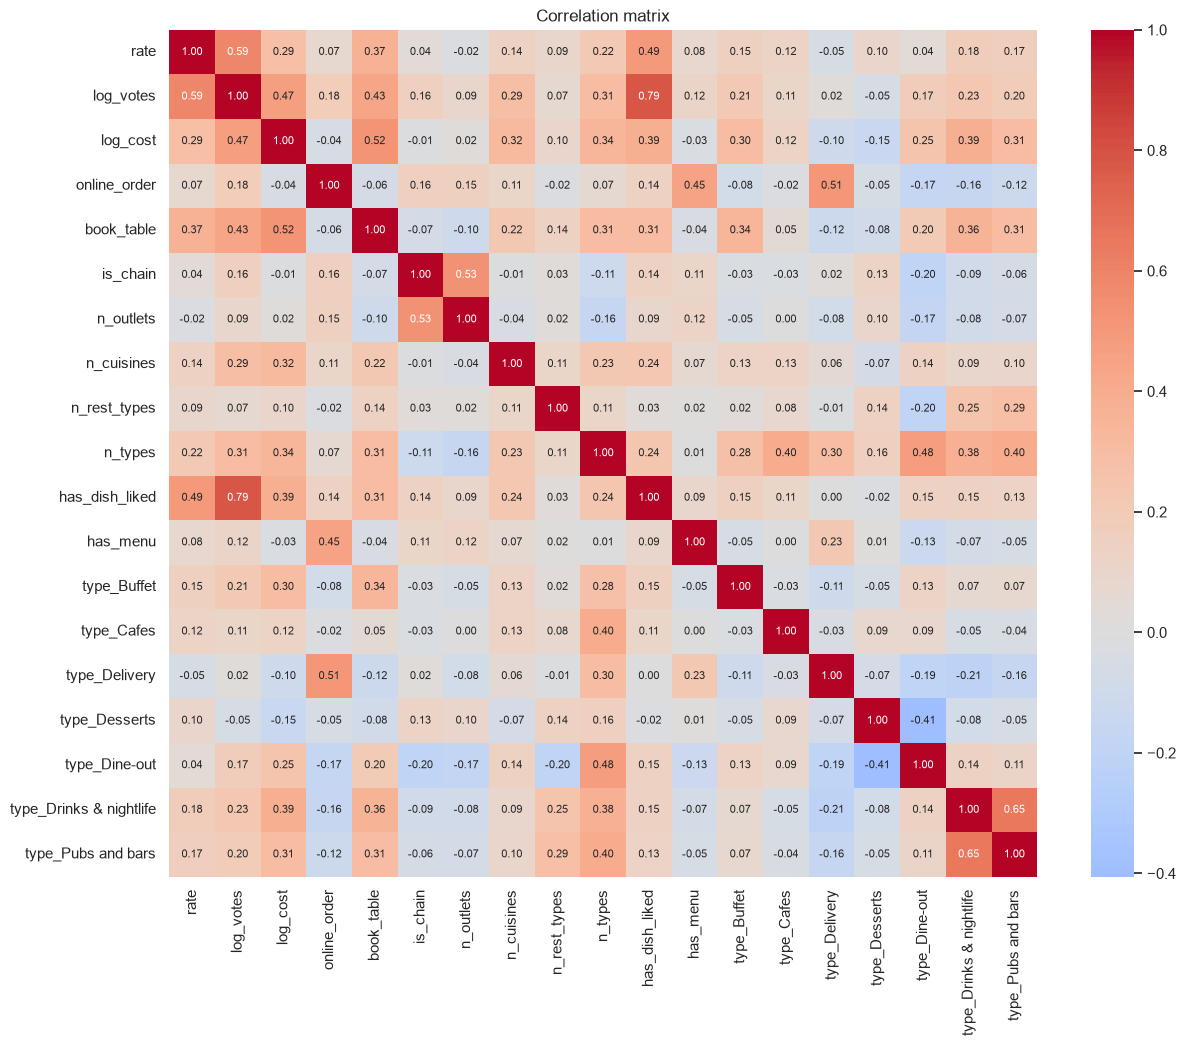

log_votes                  0.588
has_dish_liked             0.490
book_table                 0.374
log_cost                   0.286
n_types                    0.219
type_Drinks & nightlife    0.176
type_Pubs and bars         0.166
type_Buffet                0.151
n_cuisines                 0.141
type_Cafes                 0.123
type_Desserts              0.101
n_rest_types               0.092
has_menu                   0.081
online_order               0.074
type_Dine-out              0.039
is_chain                   0.038
n_outlets                 -0.018
type_Delivery             -0.052
Name: rate, dtype: float64


In [278]:
num = df_clean.copy()
num['log_votes'] = np.log1p(num['votes'])
num['log_cost']  = np.log1p(num['cost2people'])
cols = (['rate', 'log_votes', 'log_cost', 'online_order', 'book_table', 'is_chain', 'n_outlets',
         'n_cuisines', 'n_rest_types', 'n_types', 'has_dish_liked', 'has_menu'] + type_cols)
corr = num[cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation matrix'); plt.show()

print(corr['rate'].drop('rate').sort_values(ascending=False).round(3))

---

# Section 3: EDA and Preprocessing

This section has two parts:

1. **EDA:** numerical checks (outliers, correlations) and the choice of the threshold that turns `rate` into the *good / not good* label for classification.
2. **Preprocessing:** we split the data into train and test sets first, then encode `rest_type`, `cuisines` and `location`, log-transform `votes` and `cost`, and scale. Every step that learns from the data is fitted on the training set only, to avoid data leakage.

In [ ]:
df_clean.head(3)

,online_order,book_table,rate,votes,location,rest_type,cuisines,cost2people,type_Buffet,type_Cafes,...,type_Dine-out,type_Drinks & nightlife,type_Pubs and bars,n_types,n_outlets,is_chain,n_cuisines,n_rest_types,has_dish_liked,has_menu
0,1,1,4.9,16832,Sarjapur Road,Microbrewery,"Continental, North Indian, Italian, South Indi...",1600.0,0,0,...,1,1,0,3,1,0,5,1,1,0
1,0,0,4.7,14956,Indiranagar,Microbrewery,"Italian, American, Pizza",1500.0,0,0,...,1,1,0,2,1,0,3,1,1,0
2,0,0,4.7,14726,Koramangala 5th Block,"Cafe, Casual Dining","Cafe, American, Burger, Steak",900.0,0,1,...,1,0,0,3,5,1,4,2,1,0


In [127]:
num_cols = ['votes', 'cost2people', 'n_types', 'n_outlets', 'n_cuisines', 'n_rest_types']
bin_cols = ['online_order', 'book_table','is_chain','has_dish_liked', 'has_menu', 'type_Buffet', 'type_Cafes', 
            'type_Dine-out', 'type_Drinks & nightlife', 'type_Pubs and bars', 'type_Delivery', 'type_Desserts']
cat_cols = ['location', 'rest_type', 'cuisines']

In [125]:
df_clean[num_cols].describe()

,votes,cost2people,n_types,n_outlets,n_cuisines,n_rest_types
count,9438.000000,9438.000000,9438.000000,9438.000000,9438.000000,9438.000000
mean,242.534329,536.132549,1.757682,4.167196,2.418203,1.138377
std,678.856545,425.315112,0.709375,7.263273,1.227202,0.345313
min,0.000000,40.000000,1.000000,1.000000,1.000000,1.000000
25%,16.000000,300.000000,1.000000,1.000000,2.000000,1.000000
50%,53.000000,400.000000,2.000000,1.000000,2.000000,1.000000
75%,189.750000,600.000000,2.000000,3.000000,3.000000,1.000000
max,16832.000000,6000.000000,6.000000,49.000000,8.000000,2.000000


**Observation:** `votes`, `cost2people` and `n_outlets` are strongly right-skewed (means well above medians, e.g. `n_outlets` has a median of 1 but a maximum of 49), so they will be log-transformed before scaling. `n_types`, `n_cuisines` and `n_rest_types` are small counts with no extreme values; `n_rest_types` only takes the values 1 and 2. Statistics used for scaling will be computed on the training set only.

### outliers and skew

In [132]:
# Skewness
skew = df_clean[num_cols].skew().round(2)

# Outliers
q1, q3 = df_clean[num_cols].quantile(0.25), df_clean[num_cols].quantile(0.75)
iqr = q3 - q1
n_outliers = ((df_clean[num_cols] < (q1 - 1.5 * iqr)) | (df_clean[num_cols] > (q3 + 1.5 * iqr))).sum()

pd.DataFrame({'skew': skew, 'IQR outliers': n_outliers, '% rows': (n_outliers / len(df_clean) * 100).round(1)})

,skew,IQR outliers,% rows
votes,9.12,1161,12.3
cost2people,3.21,774,8.2
n_types,0.87,213,2.3
n_outlets,3.33,1448,15.3
n_cuisines,1.13,508,5.4
n_rest_types,2.09,1306,13.8


In [133]:
for t in [3.5, 3.6, 3.7, 3.8, 3.9, 4.0]:
    print(f"rate >= {t}: {(df_clean['rate'] >= t).mean():.1%} good")

rate >= 3.5: 66.6% good
rate >= 3.6: 59.2% good
rate >= 3.7: 50.7% good
rate >= 3.8: 41.1% good
rate >= 3.9: 31.9% good
rate >= 4.0: 22.9% good


**Outliers:** The IQR rule flags many rows (up to 15%), but these are genuine restaurants rather than errors, large chains (`n_outlets` up to 49). `n_rest_types` is flagged only because 86% of restaurants have a single type, so the IQR is zero. We therefore keep all rows and reduce the effect of extreme values with a log transform on `votes`, `cost2people` and `n_outlets`, the three columns with skew above 3.

**Threshold for the classification label:** We compared cut-offs for a "good" restaurant. Thresholds of 3.5 or below give a majority class of 60% or more, and 4.0 gives only 22.9% good restaurants. A threshold of **3.8** gives a reasonable 41% / 59% split and lies above the mean rating (3.63), so we define *good* as `rate >= 3.8`.

### Train, Test, Split

In [176]:
from sklearn.model_selection import train_test_split

df_clean['good'] = (df_clean['rate'] >= 3.8).astype(int)

X = df_clean.drop(columns=['rate', 'good'])
y_reg = df_clean['rate']
y_clf = df_clean['good']

X_train, X_test, y_train_reg, y_test_reg, y_train_clf, y_test_clf =  train_test_split(X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

In [177]:
print("X_train shape:\t\t\t", X_train.shape)
print("X_test shape:\t\t\t", X_test.shape)
print("y_train_regression shape:\t", y_train_reg.shape)
print("y_test_regression shape:\t", y_test_reg.shape)
print("y_train_classification shape:\t", y_train_clf.shape)
print("y_test_classification shape:\t", y_test_clf.shape)

X_train shape:			 (7550, 21)
X_test shape:			 (1888, 21)
y_train_regression shape:	 (7550,)
y_test_regression shape:	 (1888,)
y_train_classification shape:	 (7550,)
y_test_classification shape:	 (1888,)


### Multi Encoding

In [178]:
def count_values(col):
    return X_train[col].str.split(',').explode().str.strip().value_counts()

rt_counts  = count_values('rest_type')
cui_counts = count_values('cuisines')

print("Restaurant Types: " , len(rt_counts))
print("Cuisines Types: " , len(cui_counts))

Restaurant Types:  23
Cuisines Types:  102


In [179]:
rt_counts

rest_type
Quick Bites       3095
Casual Dining     1912
Delivery           783
Cafe               514
Dessert Parlor     500
Takeaway           364
Bakery             263
Beverage Shop      255
Bar                244
Food Court         143
Sweet Shop         125
Pub                 87
Fine Dining         72
Lounge              66
Kiosk               43
Mess                42
Microbrewery        40
Food Truck          17
Club                 5
Dhaba                4
Confectionery        1
Irani Cafee          1
Bhojanalya           1
Name: count, dtype: int64

In [180]:
cui_counts

cuisines
North Indian    3106
Chinese         2272
Fast Food       1311
South Indian    1289
Biryani         1047
                ... 
Sindhi             1
Cantonese          1
Hot dogs           1
Russian            1
Drinks Only        1
Name: count, Length: 102, dtype: int64

In [181]:
for m in [20, 50, 100]:
    print(f"Higher than or equal {m}:", " Restaurants:",(rt_counts >= m).sum(), " Cuisines:",(cui_counts >= m).sum())

Higher than or equal 20:  Restaurants: 17  Cuisines: 50
Higher than or equal 50:  Restaurants: 14  Cuisines: 41
Higher than or equal 100:  Restaurants: 11  Cuisines: 33


In [182]:
# categories with frequency < 20 in rest , < 50 in cuisines will be replaced with 'others' inside the string
X_train = X_train.copy()
X_test = X_test.copy()

def get_keep(col, min_count):
    counts = X_train[col].str.split(',').explode().str.strip().value_counts()
    return set(counts[counts >= min_count].index)        

def replace_rare(value, keep):
    parts = [p.strip() for p in value.split(',')]
    parts = [p if p in keep else 'others' for p in parts]
    return ', '.join(dict.fromkeys(parts))                

for col, m in [('rest_type', 20), ('cuisines', 50)]:
    keep = get_keep(col, m)
    X_train[col] = X_train[col].apply(replace_rare, keep=keep)
    X_test[col]  = X_test[col].apply(replace_rare, keep=keep)

X_train['rest_type'].value_counts().head()

rest_type
Quick Bites       2858
Casual Dining     1632
Delivery           440
Cafe               390
Dessert Parlor     367
Name: count, dtype: int64

In [183]:
# apply one-hot encoding (can be done by MultiLabelBinarizer from sklearn)
rt_train  = X_train['rest_type'].str.get_dummies(sep=', ').add_prefix('rt_')
cui_train = X_train['cuisines'].str.get_dummies(sep=', ').add_prefix('cui_')

rt_test  = X_test['rest_type'].str.get_dummies(sep=', ').add_prefix('rt_').reindex(columns=rt_train.columns, fill_value=0)
cui_test = X_test['cuisines'].str.get_dummies(sep=', ').add_prefix('cui_').reindex(columns=cui_train.columns, fill_value=0)

X_train = pd.concat([X_train.drop(columns=['rest_type', 'cuisines']), rt_train, cui_train], axis=1)
X_test  = pd.concat([X_test.drop(columns=['rest_type', 'cuisines']),  rt_test,  cui_test],  axis=1)    

In [184]:
print("X_train shape:" ,X_train.shape, "\nX_test shape:" ,X_test.shape)
print(list(X_train.columns) == list(X_test.columns)) 

X_train shape: (7550, 79) 
X_test shape: (1888, 79)
True


In [185]:
X_train.head()

,online_order,book_table,votes,location,cost2people,type_Buffet,type_Cafes,type_Delivery,type_Desserts,type_Dine-out,...,cui_Rolls,cui_Salad,cui_Sandwich,cui_Seafood,cui_South Indian,cui_Steak,cui_Street Food,cui_Tea,cui_Thai,cui_others
363,1,1,1257,Jayanagar,1000.0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
888,0,0,583,Ulsoor,700.0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
3417,0,0,104,Banaswadi,400.0,0,0,1,0,1,...,0,0,0,0,1,0,0,0,0,0
3552,0,0,96,Church Street,500.0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
6687,1,0,20,JP Nagar,150.0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [186]:
X_train = X_train.drop(columns='n_types')
X_test = X_test.drop(columns='n_types')

In [189]:
loc_counts = X_train['location'].value_counts()
keep_loc = loc_counts[loc_counts >= 50].index
X_train['location'] = X_train['location'].where(X_train['location'].isin(keep_loc), 'others')
X_test['location']  = X_test['location'].where(X_test['location'].isin(keep_loc), 'others')

In [191]:
X_train['location'].value_counts()

location
others                   1159
Whitefield                514
BTM                       439
HSR                       435
Marathahalli              406
Electronic City           369
Indiranagar               341
JP Nagar                  315
Bannerghatta Road         281
Jayanagar                 256
Sarjapur Road             204
Bellandur                 203
Koramangala 5th Block     192
Banashankari              182
New BEL Road              180
Kalyan Nagar              153
Malleshwaram              153
Basavanagudi              140
Rajajinagar               139
Banaswadi                 121
Frazer Town               116
Brookefield               109
Koramangala 6th Block     109
Kammanahalli               98
Koramangala 7th Block      95
Koramangala 1st Block      94
Old Airport Road           86
Koramangala 4th Block      81
Brigade Road               79
Ulsoor                     73
Nagawara                   70
MG Road                    68
Residency Road             66
D

In [192]:
loc_train = pd.get_dummies(X_train['location'], prefix='loc').astype(int)
loc_test  = pd.get_dummies(X_test['location'],  prefix='loc').astype(int).reindex(columns=loc_train.columns, fill_value=0)

# location columns sum to 1 so we drop 'others' and use it as the baseline
loc_train = loc_train.drop(columns='loc_others')
loc_test  = loc_test.drop(columns='loc_others')

X_train = pd.concat([X_train.drop(columns='location'), loc_train], axis=1)
X_test  = pd.concat([X_test.drop(columns='location'),  loc_test],  axis=1)

In [193]:
print(X_train.shape, X_test.shape)
print(list(X_train.columns) == list(X_test.columns))     

(7550, 113) (1888, 113)
True


### Log Transform and Scaling

In [198]:
log_cols = ['votes', 'cost2people', 'n_outlets']
for c in (X_train, X_test):
    c[log_cols] = np.log1p(c[log_cols])

In [200]:
from sklearn.preprocessing import StandardScaler

to_scale_cols = ['votes', 'cost2people', 'n_outlets', 'n_cuisines', 'n_rest_types']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[to_scale_cols] = scaler.fit_transform(X_train_scaled[to_scale_cols])
X_test_scaled[to_scale_cols] = scaler.transform(X_test_scaled[to_scale_cols])

In [201]:
X_train_scaled[to_scale_cols].describe().round(2)

,votes,cost2people,n_outlets,n_cuisines,n_rest_types
count,7550.00,7550.00,7550.00,7550.00,7550.00
mean,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.58,-3.75,-0.63,-1.14,-0.40
25%,-0.81,-0.58,-0.63,-0.33,-0.40
50%,-0.07,-0.12,-0.63,-0.33,-0.40
75%,0.70,0.52,0.25,0.48,-0.40
max,3.50,3.89,3.45,4.52,2.52


In [202]:
X_train_scaled.isna().sum().sum()

np.int64(0)

## Preprocessing Summary
- Created the classification label `good` (`rate >= 3.8`), which gives a 41% / 59% class split
- Split the data 80/20 into train and test (`random_state=42`, stratified on `good`), with `rate` and `good` removed from the features
- Counted the values of `rest_type` and `cuisines` on the training set only, and replaced rare categories (fewer than 20 and 50 restaurants respectively) with `others`
- Converted both multivalued columns into 0/1 columns, one per remaining category, so a restaurant can belong to several; the test set was forced to use the same columns as train
- Grouped `location` areas with fewer than 50 training restaurants into `others` (about 15% of the rows), then one-hot encoded it with `others` as the baseline category
- Applied a log(1 + x) transform to `votes`, `cost2people` and `n_outlets` to reduce their skew
- Standardized the numeric columns with a `StandardScaler` fitted on the training set only
- Kept two versions of the data: unscaled for the tree-based models (Decision Tree, Bagging, Boosting) and scaled for Linear/Logistic Regression, KNN, SVM and Naive Bayes
- Result: `X_train` (7550 × 113) and `X_test` (1888 × 113), with identical columns and no missing values

---

# Section 4: Modeling

We build two tracks from the same preprocessed data:

- **Regression** (target `rate`): Linear Regression, Decision Tree, KNN, SVR, Bagging, Boosting. Metrics: MAE, RMSE, R².
- **Classification** (target `good`, `rate >= 3.8`): Logistic Regression, Naive Bayes, Decision Tree, KNN, SVM, Bagging, Boosting. Metrics: accuracy, precision, recall, F1, ROC-AUC.

Each model is first trained with default settings and compared against a simple baseline (the mean rating, or the majority class). The best candidates are then tuned with cross-validation on the training set only, and every final model is evaluated once on the test set. Scaled data is used for the linear, distance-based and Naive Bayes models, and unscaled data for the tree-based models.

In [262]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [253]:
def evaluate(name, model, X_train, X_test):
    model.fit(X_train, y_train_reg)
    predictions = model.predict(X_test)
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_test_reg, predictions),
        'RMSE': root_mean_squared_error(y_test_reg, predictions),
        'R² Score': r2_score(y_test_reg, predictions),
    }

models = []

In [254]:
baseline = evaluate('Baseline', DummyRegressor(strategy='mean'), X_train, X_test)
models.append(baseline)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.43,-0.0


**Baseline (regression):** A model that always predicts the mean training rating (3.63) gives the reference scores: MAE ≈ 0.347, RMSE ≈ 0.43, R² ≈ 0. Any real model must clearly beat these numbers to be considered useful.

In [255]:
linear_regression = evaluate('Linear Regression', LinearRegression(), X_train_scaled, X_test_scaled)
models.append(linear_regression)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456


In [256]:
descision_tree_reg = evaluate('Descision Tree Regressor', DecisionTreeRegressor(max_depth=7, min_samples_leaf=3, random_state=42), X_train, X_test)
models.append(descision_tree_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431


In [257]:
tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train_reg)
print('train R2:', r2_score(y_train_reg, tree.predict(X_train)))
print('depth:', tree.get_depth(), '| leaves:', tree.get_n_leaves())

train R2: 0.9998639155486134
depth: 46 | leaves: 5736


Overfitting!!!

In [258]:
knn_reg = evaluate('KNN Regressor', KNeighborsRegressor(), X_train_scaled, X_test_scaled)
models.append(knn_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431
3,KNN Regressor,0.234,0.317,0.455


In [259]:
rf_reg = evaluate('Random Forest Regressor', RandomForestRegressor(random_state=42, n_jobs=-1), X_train, X_test)
models.append(rf_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431
3,KNN Regressor,0.234,0.317,0.455
4,Random Forest Regressor,0.219,0.305,0.496


In [260]:
xgb_reg = evaluate('XGB Regressor', XGBRegressor(random_state=42, n_jobs=-1), X_train, X_test)
models.append(xgb_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431
3,KNN Regressor,0.234,0.317,0.455
4,Random Forest Regressor,0.219,0.305,0.496
5,XGB Regressor,0.224,0.309,0.485


In [261]:
lgbm_reg = evaluate('LightGBM Regressor', LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1), X_train, X_test)
models.append(lgbm_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431
3,KNN Regressor,0.234,0.317,0.455
4,Random Forest Regressor,0.219,0.305,0.496
5,XGB Regressor,0.224,0.309,0.485
6,LightGBM Regressor,0.214,0.296,0.527


In [263]:
svr_reg = evaluate('SVR', SVR(), X_train_scaled, X_test_scaled)
models.append(svr_reg)
pd.DataFrame(models).round(3)

,Model,MAE,RMSE,R² Score
0,Baseline,0.347,0.430,-0.000
1,Linear Regression,0.230,0.317,0.456
2,Descision Tree Regressor,0.234,0.324,0.431
3,KNN Regressor,0.234,0.317,0.455
4,Random Forest Regressor,0.219,0.305,0.496
5,XGB Regressor,0.224,0.309,0.485
6,LightGBM Regressor,0.214,0.296,0.527
7,SVR,0.216,0.306,0.492


### Tuning

In [265]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score

In [266]:
def tune(model, grid, Xtr, ytr, n_iter=15, cv=5):
    rs = RandomizedSearchCV(model, grid, n_iter=n_iter, cv=cv, random_state=42, scoring='neg_root_mean_squared_error', n_jobs=-1)
    rs.fit(Xtr, ytr)
    print(f'best CV RMSE: {-rs.best_score_:.4f} | {rs.best_params_}')
    return rs.best_estimator_

In [267]:
rf_tuned = tune(
            RandomForestRegressor(random_state=42, n_jobs=-1),
            {'n_estimators': [300, 500], 'max_depth': [10, 15, 20, None],
            'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.3, 0.5]},
            X_train, y_train_reg, n_iter=12
            )

best CV RMSE: 0.3042 | {'n_estimators': 300, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': None}


In [272]:
xgb_tuned = tune(
            XGBRegressor(random_state=42, n_jobs=-1),
            {'n_estimators': [200, 400, 600], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
            'max_depth': [3, 4, 5, 6], 'min_child_weight': [1, 3, 5],
            'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'reg_lambda': [1, 5]},
            X_train, y_train_reg, n_iter=20)

best CV RMSE: 0.3029 | {'subsample': 0.85, 'reg_lambda': 5, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [269]:
lgbm_tuned = tune(
            LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1, subsample_freq=1),
            {'n_estimators': [200, 400, 600], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
            'num_leaves': [15, 31, 63], 'min_child_samples': [10, 20, 40],
            'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'reg_lambda': [0, 1, 5]},
            X_train, y_train_reg, n_iter=20)

best CV RMSE: 0.3017 | {'subsample': 0.85, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 40, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [270]:
def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train_reg, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1).mean()

In [273]:
pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'LightGBM'],
    'CV RMSE default': [cv_rmse(RandomForestRegressor(random_state=42, n_jobs=-1)),
                        cv_rmse(XGBRegressor(random_state=42, n_jobs=-1)),
                        cv_rmse(LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1))],
    'CV RMSE tuned':   [cv_rmse(rf_tuned), cv_rmse(xgb_tuned), cv_rmse(lgbm_tuned)]}).round(4)

,Model,CV RMSE default,CV RMSE tuned
0,Random Forest,0.3116,0.3042
1,XGBoost,0.3174,0.3029
2,LightGBM,0.3022,0.3017


In [275]:
final_models = {'Random Forest': rf_tuned, 'XGBoost': xgb_tuned, 'LightGBM': lgbm_tuned}

rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Train RMSE': root_mean_squared_error(y_train_reg, model.predict(X_train)),
        'Train MAE': mean_absolute_error(y_train_reg, model.predict(X_train)),
        'Train R²': r2_score(y_train_reg, model.predict(X_train)),
        'CV RMSE': cv_rmse(model),
        'Test MAE': mean_absolute_error(y_test_reg, pred),
        'Test RMSE': root_mean_squared_error(y_test_reg, pred),
        'Test R²': r2_score(y_test_reg, pred),
    })

results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))

,Train RMSE,Train MAE,Train R²,CV RMSE,Test MAE,Test RMSE,Test R²
Model,,,,,,,
Random Forest,0.2180,0.1564,0.7431,0.3042,0.2127,0.2951,0.5293
XGBoost,0.2391,0.1736,0.6907,0.3029,0.2130,0.2946,0.5308
LightGBM,0.2725,0.2000,0.5983,0.3017,0.2136,0.2945,0.5312
